<!-- # Setup -->

pineapple yield prediction

# Setup

In [975]:
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    RocCurveDisplay,
    auc,
    confusion_matrix,
    mutual_info_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm

import xgboost as xgb

%matplotlib inline

In [976]:
# Load Data

psa_area_data = pd.read_csv('data/normalized/psa_area_long.csv')
psa_prod_data = pd.read_csv('data/normalized/psa_production_long.csv')
# psa_farmgate = pd.read_csv('data/normalized/psa_farmgate_long.csv') # use only for valuation
# psa_ppa      = pd.read_csv('data/normalized/psa_ppa_long.csv')      # use only for context
noaa_enso_data    = pd.read_csv('data/normalized/noaa_enso_long.csv')
nasa_weather_data = pd.read_csv('data/normalized/nasa_weather_long.csv')

In [977]:
# The problem: pineapple production volatility in SOCCSKSARGEN and the cost of late intervention.
# The method: self-collected weather and production data, feature engineering, and a model designed to trigger early warning rather than post-hoc explanation.
# The policy use: how a regional planning office could use such a system for monitoring, early intervention, and investment targeting in agro-industrial value chains.

# production + area        â†’ yield_mt_ha        (done)
# + lagged weather         â†’ features
# + lagged ONI             â†’ feature
# + prev_yield, area       â†’ features
# â†’ model yield

<!-- # Data Preparation

For data inclusion/exclusion â€” see docs/data_dictionary.md -->

# Data Processing

## PSA

In [942]:
# area and prod have the same schema

area_prod_cols = ['crop', 'geo_level_name', 'region_name', 'province_name', 'year', 'period_type', 'period', 'value']

<!-- ## PSA -->

In [943]:
# trim columns, merge PSA data, rename and format

psa_area = psa_area_data[area_prod_cols]
psa_prod = psa_prod_data[area_prod_cols]

psa = psa_area.rename(columns={'value': 'area_ha'}).merge(
      psa_prod.rename(columns={'value': 'prod_mt'}),
    on=['crop', 'geo_level_name', 'region_name', 'province_name', 'year', 'period_type', 'period'],
    how='left', validate='one_to_one'
)

psa_str_cols = list(psa_area.select_dtypes(include='str').columns)

for c in psa_str_cols:
    psa[c] = psa[c].str.lower().str.replace(' ', '_')

psa = psa.rename(columns={
    'geo_level_name': 'level',
    'region_name': 'region',
    'province_name': 'province'
})

psa['yield'] = psa['prod_mt'] / psa['area_ha'] # add yield - target variable

psa[psa.province == 'south_cotabato'].sort_values(['year', 'period'], ascending=False).head() # check data for so cot

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
12964,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester2,NaN,NaN,NaN
12634,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester1,23018.0,403071.0,17.511122
12854,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter4,NaN,NaN,NaN
12744,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter3,NaN,NaN,NaN
12524,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter2,23018.0,199108.0,8.650100


In [944]:
psa = psa[(psa['yield'].notna()) & (psa['yield'] > 0)] # exclude missing yield data

cols = ['level', 'period_type'] # check best level and period for model

for c in cols:
    print(f"{psa[c].value_counts().sort_values(ascending=False)}\n{'-' * 25}")

# best level and period: provincial and semestral

level
province    4072
region       893
city          94
national      55
Name: count, dtype: int64
-------------------------
period_type
semester    3058
annual      1515
quarter      541
Name: count, dtype: int64
-------------------------


In [945]:
psa = psa[(psa['level'] == 'province') & (psa['period_type'] == 'semester')].reset_index(drop=True) # limit to semestral, provincial

psa[psa.province == 'south_cotabato'].sort_values(['year', 'period'], ascending=False).head().round(2) # check data for so cot

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
2425,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester1,23018.0,403071.00,17.51
2346,pineapple,province,region_xii_(soccsksargen),south_cotabato,2025,semester,semester2,22554.0,386100.44,17.12
2270,pineapple,province,region_xii_(soccsksargen),south_cotabato,2025,semester,semester1,23283.0,393859.30,16.92
2193,pineapple,province,region_xii_(soccsksargen),south_cotabato,2024,semester,semester2,23148.0,397940.60,17.19
2121,pineapple,province,region_xii_(soccsksargen),south_cotabato,2024,semester,semester1,23400.0,386566.39,16.52


In [946]:
psa.info() # check for nulls (none)

<class 'pandas.DataFrame'>
RangeIndex: 2435 entries, 0 to 2434
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   crop         2435 non-null   str    
 1   level        2435 non-null   str    
 2   region       2435 non-null   str    
 3   province     2435 non-null   str    
 4   year         2435 non-null   int64  
 5   period_type  2435 non-null   str    
 6   period       2435 non-null   str    
 7   area_ha      2435 non-null   float64
 8   prod_mt      2435 non-null   float64
 9   yield        2435 non-null   float64
dtypes: float64(3), int64(1), str(6)
memory usage: 362.3 KB


In [947]:
psa.describe().round() # check data distribution

# wide gap between mean and std

,year,area_ha,prod_mt,yield
count,2435.0,2435.0,2435.0,2435.0
mean,2018.0,840.0,17832.0,8.0
std,5.0,3869.0,96043.0,34.0
min,2010.0,0.0,0.0,0.0
25%,2014.0,8.0,24.0,2.0
50%,2018.0,32.0,103.0,5.0
75%,2022.0,200.0,643.0,9.0
max,2026.0,30507.0,960128.0,1621.0


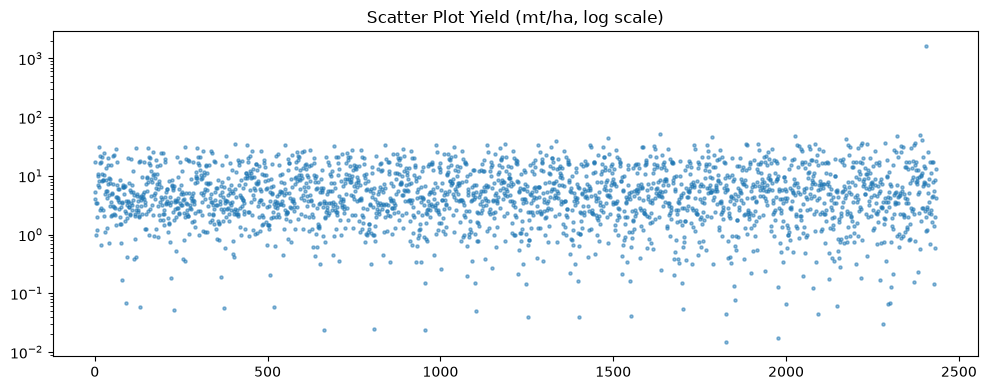

In [948]:
# visually check yield distribution

plt.figure(figsize=(10, 4))
plt.scatter(psa.index, psa['yield'], s=5, alpha=0.5)
plt.yscale('log')
plt.title('Scatter Plot Yield (mt/ha, log scale)')
plt.tight_layout()
plt.show()

# max yield of 1621, a potential error

In [949]:
psa.sort_values('yield', ascending=False).head() # unusual data came from Samar 2026 sem1

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
2406,pineapple,province,region_viii_(eastern_visayas),samar,2026,semester,semester1,4.20,6809.99,1621.426190
1635,pineapple,province,region_v_(bicol_region),camarines_norte,2021,semester,semester1,2341.06,123067.54,52.569152
2387,pineapple,province,region_v_(bicol_region),camarines_norte,2026,semester,semester1,2690.72,135845.21,50.486565
2025,pineapple,province,region_viii_(eastern_visayas),eastern_samar,2023,semester,semester2,29.03,1374.50,47.347571
2321,pineapple,province,negros_island_region_(nir),siquijor,2025,semester,semester2,0.05,2.34,46.800000


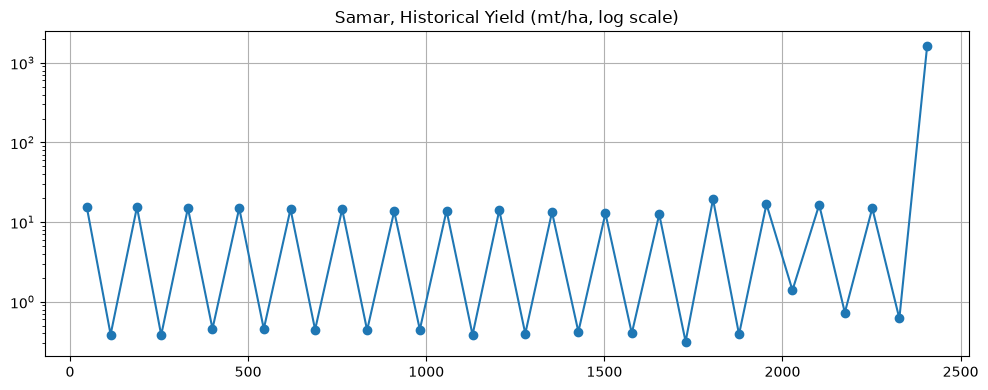

In [950]:
# check and confirm Samar historical yield

psa[psa['province'] == 'samar']['yield'].plot(figsize=(10, 4), marker='o', logy=True, grid=True,
    title='Samar, Historical Yield (mt/ha, log scale)'
    )

plt.tight_layout()
plt.show()

# unusual indeed, likely an error

In [951]:
psa = psa[(psa['yield'] < 100)] # drop implausible yields

psa.describe().round() # better - mean and std, the same

,year,area_ha,prod_mt,yield
count,2434.0,2434.0,2434.0,2434.0
mean,2018.0,840.0,17836.0,7.0
std,5.0,3870.0,96062.0,7.0
min,2010.0,0.0,0.0,0.0
25%,2014.0,8.0,24.0,2.0
50%,2018.0,32.0,103.0,5.0
75%,2022.0,200.0,642.0,9.0
max,2026.0,30507.0,960128.0,53.0


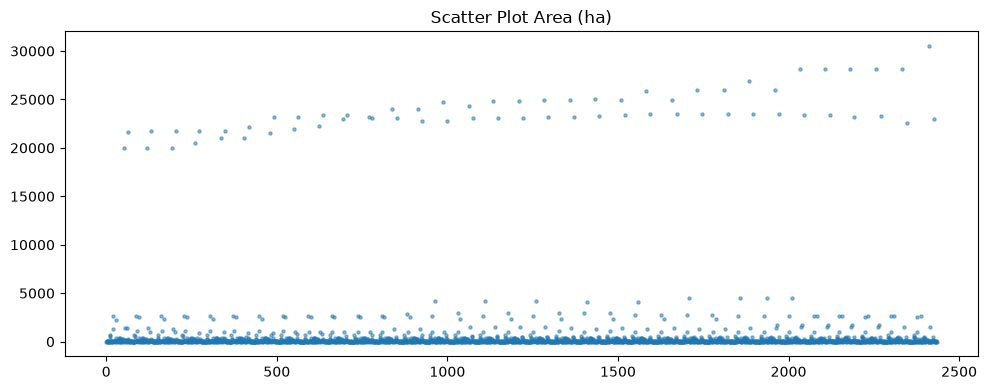

In [952]:
# visually check area distribution

plt.figure(figsize=(10, 4))
plt.scatter(psa.index, psa.area_ha, s=5, alpha=0.5)
plt.title('Scatter Plot Area (ha)')
plt.tight_layout()
plt.show()

# immaterial provinces could be noise, set a minimum

In [953]:
# get share of total to measure materiality

psa['area_share'] = psa['area_ha'] / psa['area_ha'].sum()
psa['prod_share'] = psa['prod_mt'] / psa['prod_mt'].sum()

In [954]:
# get cumulative prod share at given minimum area ha

for a in [10, 20, 50, 100, 200, 300, 400, 500, 750, 1e3, 2e3, 3e3, 4e3, 5e3]:
    segment = psa[psa['area_ha'] < a]
    print(f"{a:,.0f} ha: {(segment.prod_share.sum()):.2%} ({(segment.prod_share.count()):,.0f})")

# check for less than half of one percent

10 ha: 0.04% (747)
20 ha: 0.08% (1,026)
50 ha: 0.26% (1,473)
100 ha: 0.47% (1,717)
200 ha: 0.60% (1,822)
300 ha: 1.18% (1,951)
400 ha: 2.29% (2,090)
500 ha: 3.40% (2,178)
750 ha: 4.27% (2,226)
1,000 ha: 4.62% (2,236)
2,000 ha: 7.34% (2,302)
3,000 ha: 14.01% (2,359)
4,000 ha: 14.01% (2,359)
5,000 ha: 15.33% (2,368)


In [955]:
# give up 1,717 rows but still keep 99.53% of production

psa = psa[(psa['area_ha'] >= 100)]

del psa['area_share']
del psa['prod_share']

psa.describe().round(2)

 # project requirement is >500 rows

,year,area_ha,prod_mt,yield
count,717.00,717.00,717.00,717.00
mean,2017.73,2797.99,60263.41,11.64
std,4.78,6741.64,169710.51,9.24
min,2010.00,100.00,22.66,0.02
25%,2014.00,260.00,1096.96,4.30
50%,2018.00,386.00,4030.17,9.16
75%,2022.00,1036.00,13592.20,16.96
max,2026.00,30506.59,960128.38,52.57


### Observations

Area big jump through 2023 and has been flat to slightly lower since. 
Production and yield are higher in semester 2 in most years; 2020 and 2021 are exceptions. 2026 has semester 1 only.

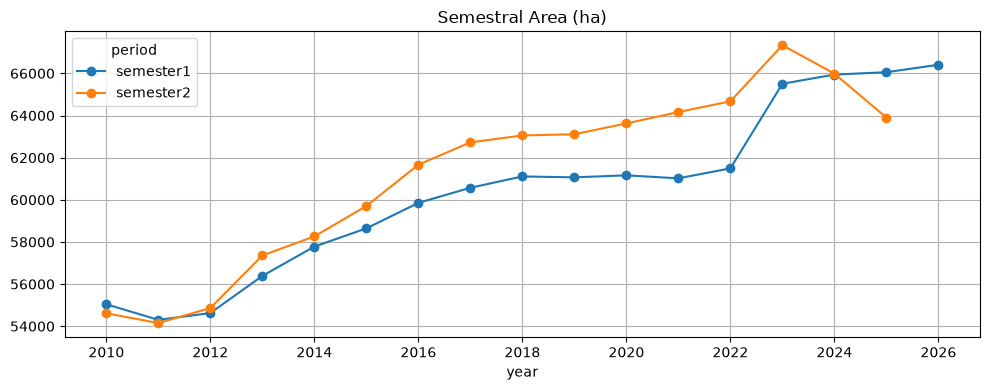

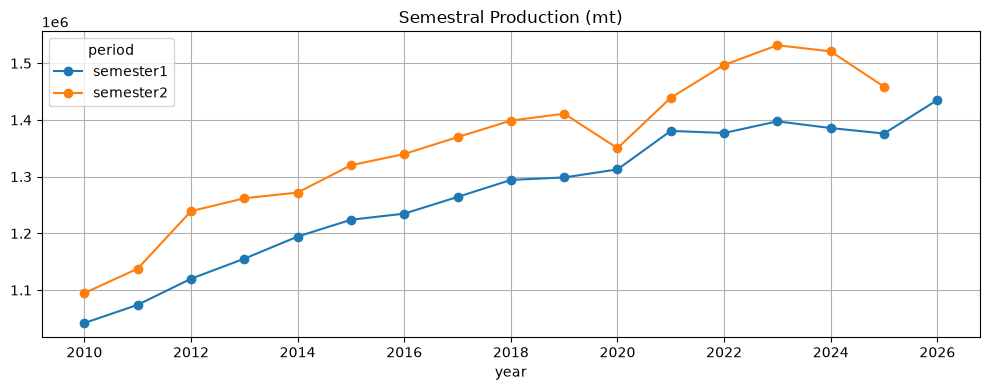

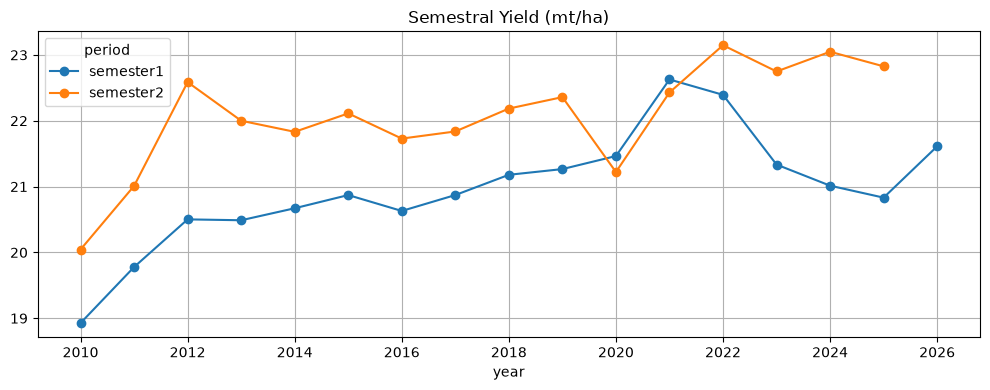

In [956]:
psa_semestral = psa.groupby(['year', 'period'], as_index=False)[['area_ha', 'prod_mt']].sum()
psa_semestral['yield'] = psa_semestral['prod_mt'] / psa_semestral['area_ha']

psa_semestral.pivot(index='year', columns='period', values='area_ha'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Area (ha)'
)
plt.tight_layout()

psa_semestral.pivot(index='year', columns='period', values='prod_mt'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Production (mt)', 
)
plt.tight_layout()

psa_semestral.pivot(index='year', columns='period', values='yield'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Yield (mt/ha)', 
)
plt.tight_layout()


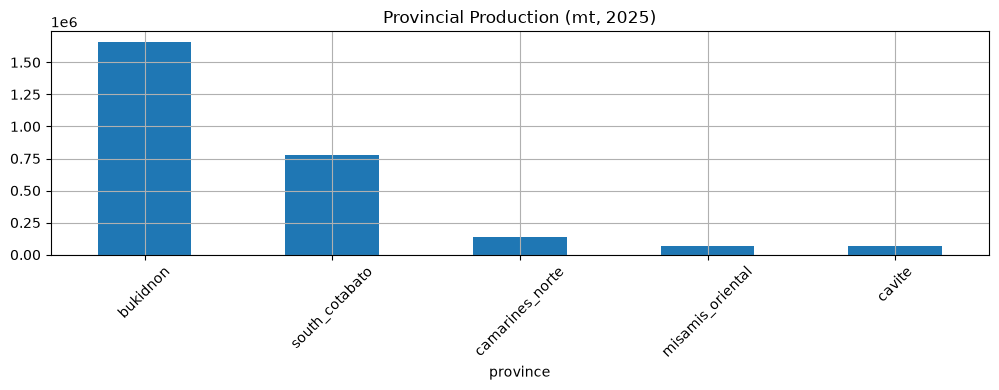

In [957]:
psa_annual_provinces = psa.groupby(['year', 'province'], as_index=False)[['prod_mt']].sum()

psa_semestral_provinces = psa.groupby(['year', 'province', 'period'], as_index=False)[['area_ha', 'prod_mt']].sum()
psa_semestral_provinces['yield'] = psa_semestral_provinces['prod_mt'] / psa_semestral_provinces['area_ha']

psa_annual_provinces[psa_annual_provinces['year'] == 2025].sort_values('prod_mt', ascending=False).head()

# top producing regions last full year cycle
(
    psa_annual_provinces[psa_annual_provinces['year'] == 2025]
    .sort_values('prod_mt', ascending=False).head()
    .set_index('province')['prod_mt']
    .plot(kind='bar', figsize=(10, 4), grid=True,
          title='Provincial Production (mt, 2025)', rot=45)
)
plt.tight_layout()

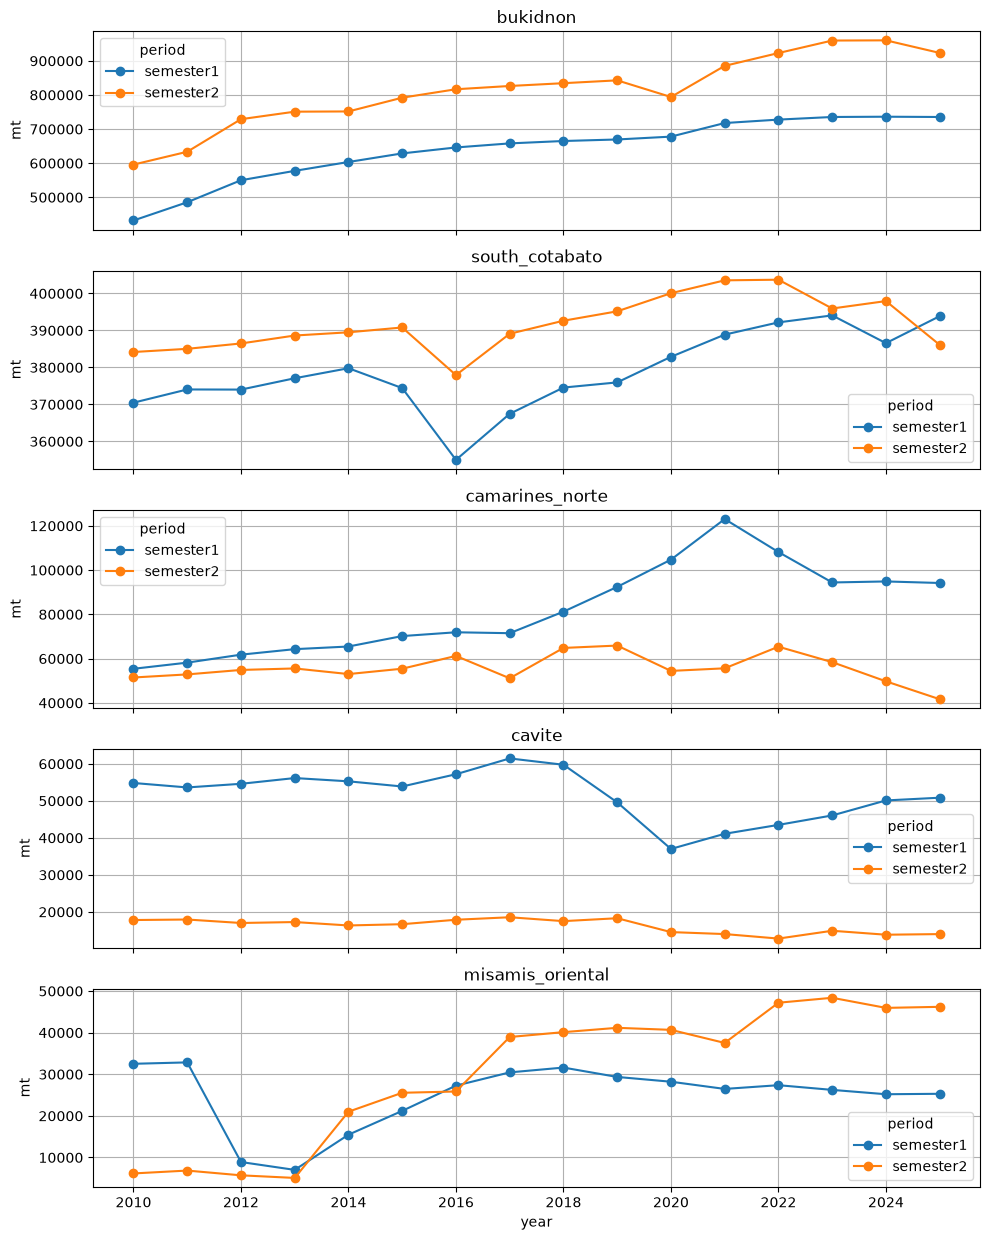

In [958]:
top_provinces = (
    psa_semestral_provinces.groupby('province')['prod_mt'].sum()
    .sort_values(ascending=False).head(5).index
)

fig, axes = plt.subplots(len(top_provinces), 1, figsize=(10, 2.5 * len(top_provinces)), sharex=True)

for ax, prov in zip(axes, top_provinces):
    sub = psa_semestral_provinces[
        (psa_semestral_provinces['province'] == prov) &
        (psa_semestral_provinces.year < 2026)
    ]
    for period, g in sub.groupby('period'):
        g.sort_values('year').plot(x='year', y='prod_mt', ax=ax, marker='o', label=period)
    ax.set_title(prov)
    ax.set_ylabel('mt')
    ax.grid(True)
    ax.legend(title='period')

plt.tight_layout()
plt.show()

# initial impression: top provinces from Mindanao stronger on semester2, Luzon on semester1

## NOAA

In [959]:
noaa_enso_data.head()

,season,year,total,anomaly
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


In [960]:
# isolate then average, to match psa semestral data
noaa = noaa_enso_data[noaa_enso_data['season'].isin(['JFM', 'AMJ', 'JAS', 'OND'])]
semester = {'JFM': 'semester1', 'AMJ': 'semester1', 'JAS': 'semester2', 'OND': 'semester2'}
noaa['period'] = noaa['season'].map(semester)
noaa = (
    noaa.dropna(subset=['period'])
    .groupby(['year', 'period'], as_index=False)
    .agg(oni_anom=('anomaly', 'mean'), n_seasons=('season', 'size'))
)
noaa.loc[noaa['n_seasons'] < 2, 'oni_anom'] = pd.NA
noaa = noaa.drop(columns='n_seasons')

noaa.tail()

,year,period,oni_anom
149,2024,semester2,-0.165
150,2025,semester1,-0.130
151,2025,semester2,-0.435
152,2026,semester1,0.370
153,2026,semester2,NaN


In [961]:
noaa = noaa.sort_values(['year', 'period']).reset_index(drop=True)
noaa = noaa.rename(columns={'oni_anom': 'oni_anom_sem'})

# check if previous anom can predict yield

noaa['oni_anom_prev1'] = noaa['oni_anom_sem'].shift(1)
noaa['oni_anom_prev2'] = noaa['oni_anom_sem'].shift(2)
noaa['oni_anom_prev3'] = noaa['oni_anom_sem'].shift(3)
noaa['oni_anom_prev4'] = noaa['oni_anom_sem'].shift(4)

noaa = noaa[noaa['year'] >= 2010] # match earliest psa data

# assert noaa['oni_anom_prev'].notna().all()

noaa.tail()

,year,period,oni_anom_sem,oni_anom_prev1,oni_anom_prev2,oni_anom_prev3,oni_anom_prev4
149,2024,semester2,-0.165,0.980,1.575,0.065,-0.800
150,2025,semester1,-0.130,-0.165,0.980,1.575,0.065
151,2025,semester2,-0.435,-0.130,-0.165,0.980,1.575
152,2026,semester1,0.370,-0.435,-0.130,-0.165,0.980
153,2026,semester2,NaN,0.370,-0.435,-0.130,-0.165


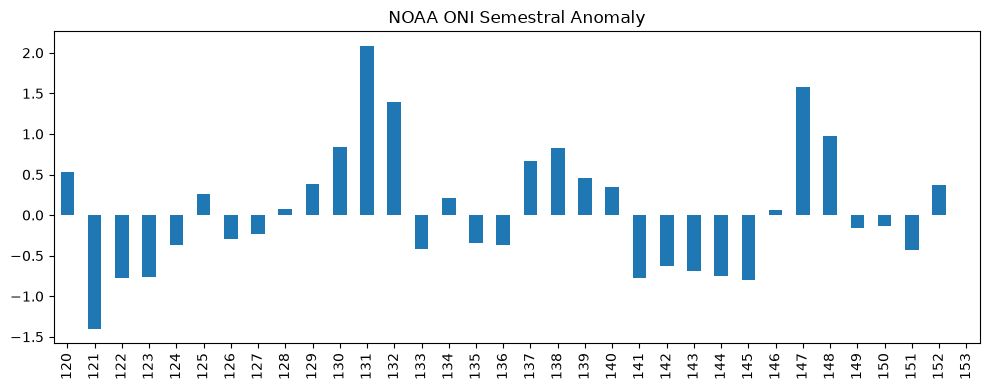

In [962]:
# plot historical semestral anomaly; +/-0.5 is considered significant

noaa.oni_anom_sem.plot(
    kind='bar', figsize=(10, 4),
    title='NOAA ONI Semestral Anomaly'
)

plt.tight_layout()

In [963]:
# merge with psa

psa_noaa = psa.merge(noaa,
    on=['year', 'period'],
    how='left', validate='many_to_one'
)

In [964]:
psa_noaa.info()

<class 'pandas.DataFrame'>
RangeIndex: 717 entries, 0 to 716
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   crop            717 non-null    str    
 1   level           717 non-null    str    
 2   region          717 non-null    str    
 3   province        717 non-null    str    
 4   year            717 non-null    int64  
 5   period_type     717 non-null    str    
 6   period          717 non-null    str    
 7   area_ha         717 non-null    float64
 8   prod_mt         717 non-null    float64
 9   yield           717 non-null    float64
 10  oni_anom_sem    717 non-null    float64
 11  oni_anom_prev1  717 non-null    float64
 12  oni_anom_prev2  717 non-null    float64
 13  oni_anom_prev3  717 non-null    float64
 14  oni_anom_prev4  717 non-null    float64
dtypes: float64(8), int64(1), str(6)
memory usage: 133.9 KB


## NASA

In [965]:
nasa = nasa_weather_data
nasa_str_cols = nasa.select_dtypes(include='str')

for c in nasa_str_cols:
    nasa[c] = nasa[c].str.lower().str.replace(' ', '_')

nasa.head()

,region_name,province_name,year,month,parameter,unit,value
0,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,1,allsky_sfc_sw_dwn,mj/m^2/day,16.22
1,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,2,allsky_sfc_sw_dwn,mj/m^2/day,18.53
2,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,3,allsky_sfc_sw_dwn,mj/m^2/day,19.91
3,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,4,allsky_sfc_sw_dwn,mj/m^2/day,19.75
4,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,5,allsky_sfc_sw_dwn,mj/m^2/day,19.57


In [966]:
# dataset has 6 parameters

nasa.parameter.values.value_counts()

allsky_sfc_sw_dwn    19350
prectotcorr          19350
rh2m                 19350
t2m                  19350
t2m_max              19350
t2m_min              19350
Name: count, dtype: int64

In [967]:
# convert monthly to semestral: precipitation as total, others avg

nasa['period'] = nasa['month'].le(6).map({True: 'semester1', False: 'semester2'})
nasa['days_in_month'] = pd.to_datetime(
    nasa[['year', 'month']].assign(day=1)
).dt.days_in_month
nasa['value_total'] = nasa['value'] * nasa['days_in_month']

nasa_sem = (
    nasa.groupby(
        ['region_name', 'province_name', 'year', 'period', 'parameter', 'unit'],
        as_index=False
    )
    .agg(value=('value', 'mean'), value_total=('value_total', 'sum'))
    .rename(columns={'region_name': 'region', 'province_name': 'province'})
)

precip = nasa_sem['parameter'].eq('prectotcorr')
nasa_sem.loc[precip, 'value'] = nasa_sem.loc[precip, 'value_total'].where(
    nasa_sem.loc[precip, 'value'].notna()
)
nasa_sem.loc[precip, 'unit'] = 'mm'
nasa_sem = nasa_sem.drop(columns='value_total')

nasa_sem.head()


,region,province,year,period,parameter,unit,value
0,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,allsky_sfc_sw_dwn,mj/m^2/day,18.646667
1,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,prectotcorr,mm,903.360000
2,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,rh2m,%,81.565000
3,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,t2m,c,27.500000
4,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,t2m_max,c,29.261667


In [968]:
# pivot one column per parameter

nasa_wide = nasa_sem.pivot(
    index=['region', 'province', 'year', 'period'],
    columns='parameter',
    values='value'
).reset_index()

# shift one semester: (Y, S1) <- (Y-1, S2); (Y, S2) <- (Y, S1)

nasa_wide['year'] = nasa_wide['year'] + nasa_wide['period'].eq('semester2').astype(int)
nasa_wide['period'] = nasa_wide['period'].map(
    {'semester1': 'semester2', 'semester2': 'semester1'}
)
nasa_wide = nasa_wide.rename(columns={
    c: f'{c}_prev' for c in nasa_wide.columns
    if c not in ['region', 'province', 'year', 'period']
})

# merge data with psa and noaa

psa_noaa_nasa = psa_noaa.merge(
    nasa_wide,
    on=['region', 'province', 'year', 'period'],
    how='left', validate='many_to_one'
)

# assert len(psa_noaa_nasa) == len(psa)
# assert psa_noaa_nasa.filter(like='_prev').notna().all().all()

psa_noaa_nasa.info()


<class 'pandas.DataFrame'>
RangeIndex: 717 entries, 0 to 716
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   crop                    717 non-null    str    
 1   level                   717 non-null    str    
 2   region                  717 non-null    str    
 3   province                717 non-null    str    
 4   year                    717 non-null    int64  
 5   period_type             717 non-null    str    
 6   period                  717 non-null    str    
 7   area_ha                 717 non-null    float64
 8   prod_mt                 717 non-null    float64
 9   yield                   717 non-null    float64
 10  oni_anom_sem            717 non-null    float64
 11  oni_anom_prev1          717 non-null    float64
 12  oni_anom_prev2          717 non-null    float64
 13  oni_anom_prev3          717 non-null    float64
 14  oni_anom_prev4          717 non-null    float64
 15  

In [969]:
# # Data validation: invariants on the feature frame.
# # This is not model validation (train/validation/test splits). It only checks
# # that the merged table is complete, unique, and correctly lagged.

# assert len(psa_noaa_nasa) == len(psa)
# assert not psa_noaa_nasa.duplicated(['region', 'province', 'year', 'period']).any()
# assert psa_noaa_nasa.notna().all().all()

# # 2010-2025 have both semesters; 2026 has S1 only

# assert psa_noaa_nasa.loc[psa_noaa_nasa.year == 2026, 'period'].unique().tolist() == ['semester1']
# assert psa_noaa_nasa.groupby('year')['period'].nunique().loc[2010:2025].eq(2).all()

# # ONI: 2026 S2 is null, range sane, lag spot check

# assert noaa.loc[(noaa.year == 2026) & (noaa.period == 'semester2'), 'oni_anom_sem'].isna().all()
# assert noaa['oni_anom_sem'].dropna().between(-4, 4).all()
# oni = noaa.loc[(noaa.year == 2026) & (noaa.period == 'semester1'), 'oni_anom_prev'].iloc[0]
# assert abs(oni + 0.435) < 1e-9

# # NASA: full grid, unique keys, units, lag spot check

# assert len(nasa_sem) == 19_440
# assert not nasa_sem.duplicated(['region', 'province', 'year', 'period', 'parameter']).any()
# assert nasa_sem.query("parameter == 'prectotcorr'")['unit'].eq('mm').all()
# t2m = psa_noaa_nasa.loc[(psa_noaa_nasa.province == 'benguet') & (psa_noaa_nasa.year == 2010), 't2m_prev'].iloc[0]
# assert abs(t2m - 22.616667) < 1e-6

# print('validation passed:', psa_noaa_nasa.shape)


<!-- # Data Modelling -->

In [970]:
# df = psa_noaa_nasa.copy()

# n = len(df)
# n_val = int(n * 0.2)
# n_test = int(n * 0.2)
# n_train = n - n_val - n_test

# rng = np.random.default_rng(seed=2)
# idx = rng.permutation(n)

# df_train = df.iloc[idx[:n_train]]
# df_val = df.iloc[idx[n_train:n_train + n_val]]
# df_test = df.iloc[idx[n_train + n_val:]]

# df_train = df_train.reset_index(drop=True)
# df_val = df_val.reset_index(drop=True)
# df_test = df_test.reset_index(drop=True)

# # the target is skewed: model log(1 + price)
# y_train = np.log1p(df_train['yield'].values)
# y_val = np.log1p(df_val['yield'].values)
# y_test = np.log1p(df_test['yield'].values)

# del df_train['yield']
# del df_val['yield']
# del df_test['yield']

# len(df_train), len(df_val), len(df_test)

In [971]:
# fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# sns.histplot(df['yield'], bins=50, ax=ax[0])
# ax[0].set_title('Yield (mt/ha)')

# sns.histplot(np.log1p(df['yield']), bins=50, ax=ax[1])
# ax[1].set_title('log(1 + yield)')

# plt.tight_layout()

In [972]:
# base = ['oni_anom_prev', 'allsky_sfc_sw_dwn_prev', 'prectotcorr_prev', 'rh2m_prev', 't2m_prev', 't2m_max_prev', 't2m_min_prev']

# X_train = df_train[base]
# X_val = df_val[base]

# model = Pipeline([  # sklearn.pipeline
#     ('impute', SimpleImputer(strategy='constant', fill_value=0)),  # sklearn.impute
#     ('regression', LinearRegression()),  # sklearn.linear_model
# ])

# model.fit(X_train, y_train)

# y_pred = model.predict(X_val)
# print('baseline RMSE: %.3f' % root_mean_squared_error(y_val, y_pred))  # sklearn.metrics

In [973]:
# base = ['oni_anom_prev', 'allsky_sfc_sw_dwn_prev', 'prectotcorr_prev', 'rh2m_prev', 't2m_prev', 't2m_max_prev', 't2m_min_prev']

# for f in base:
#     X_train = df_train[[f]]
#     X_val = df_val[[f]]

#     model = Pipeline([
#         ('impute', SimpleImputer(strategy='constant', fill_value=0)),
#         ('regression', LinearRegression()),
#     ])

#     model.fit(X_train, y_train)

#     y_pred = model.predict(X_val)
#     print(f'{f} RMSE: %.3f' % root_mean_squared_error(y_val, y_pred))